In [ ]:
# Import Libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    cross_val_predict
)

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    recall_score,
    precision_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    make_scorer
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [ ]:
# First 5 Rows
display(df.head())

# Dataset Shape
print("Dataset Shape:", df.shape)

# Dataset Information
df.info()

# Statistical Summary
display(df.describe(include='all'))

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Dataset Shape: (7043, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,7043,7043,7043.000000,7043,7043,7043.000000,7043,7043,7043,7043,...,7043,7043,7043,7043,7043,7043,7043,7043.000000,7043,7043
unique,7043,2,NaN,2,2,NaN,2,3,3,3,...,3,3,3,3,3,2,4,NaN,6531,2
top,7590-VHVEG,Male,NaN,No,No,NaN,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,,No
freq,1,3555,NaN,3641,4933,NaN,6361,3390,3096,3498,...,3095,3473,2810,2785,3875,4171,2365,NaN,11,5174
mean,NaN,NaN,0.162147,NaN,NaN,32.371149,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.761692,NaN,NaN
std,NaN,NaN,0.368612,NaN,NaN,24.559481,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.090047,NaN,NaN
min,NaN,NaN,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.250000,NaN,NaN
25%,NaN,NaN,0.000000,NaN,NaN,9.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.500000,NaN,NaN
50%,NaN,NaN,0.000000,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.350000,NaN,NaN
75%,NaN,NaN,0.000000,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.850000,NaN,NaN


In [ ]:
# Convert TotalCharges to numeric
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"].astype(str).str.strip(),
    errors="coerce"
)

# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Display rows with missing TotalCharges
display(df[df["TotalCharges"].isnull()])

# Fill missing TotalCharges with 0
df["TotalCharges"] = df["TotalCharges"].fillna(0)

# Verify missing values
print("\nMissing TotalCharges after cleaning:")
print(df["TotalCharges"].isnull().sum())

Missing Values:
customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No



Missing TotalCharges after cleaning:
0


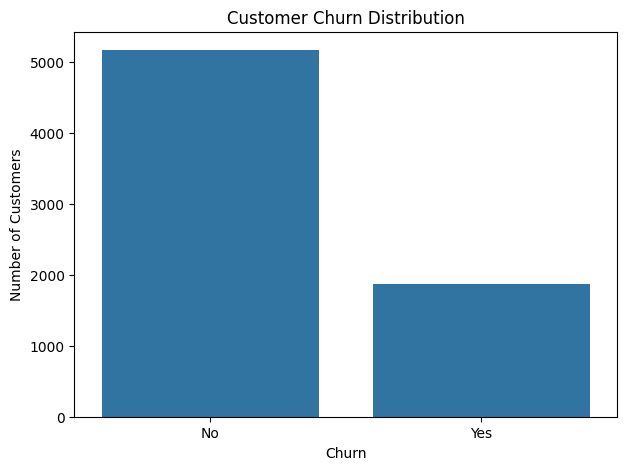

In [ ]:
# Customer Churn Distribution

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Churn"
)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

In [ ]:
# Remove customerID
df.drop("customerID", axis=1, inplace=True)

print("customerID column removed successfully!")

display(df.head())

customerID column removed successfully!


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
# Separate Features and Target

X = df.drop("Churn", axis=1)
y = df["Churn"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (7043, 19)
Target Shape: (7043,)


In [ ]:
# Split Dataset

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting Target Distribution:")
print(y_test.value_counts(normalize=True))

Training Shape: (5634, 19)
Testing Shape: (1409, 19)

Training Target Distribution:
Churn
No     0.734647
Yes    0.265353
Name: proportion, dtype: float64

Testing Target Distribution:
Churn
No     0.734564
Yes    0.265436
Name: proportion, dtype: float64


In [ ]:
# Identify Categorical and Numerical Columns

categorical_columns = X_train.select_dtypes(
    include=["object"]
).columns

numerical_columns = X_train.select_dtypes(
    include=np.number
).columns

print("Categorical Columns:")
print(categorical_columns.tolist())

print("\nNumerical Columns:")
print(numerical_columns.tolist())

Categorical Columns:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Numerical Columns:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']


In [ ]:
# Preprocessing

preprocessor = ColumnTransformer(
    transformers=[
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_columns
        ),
        (
            "num",
            StandardScaler(),
            numerical_columns
        )
    ]
)

# Build Logistic Regression Pipeline

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=3000,
        class_weight="balanced",
        random_state=42
    ))
])

# Train Model

model.fit(X_train, y_train)

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


In [ ]:
# Stratified 5-Fold Cross Validation

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluation Metrics

scoring = {
    "accuracy": "accuracy",
    "recall": make_scorer(
        recall_score,
        pos_label="Yes"
    ),
    "precision": make_scorer(
        precision_score,
        pos_label="Yes"
    ),
    "f1": make_scorer(
        f1_score,
        pos_label="Yes"
    )
}

# Run Cross Validation

cv_results = cross_validate(
    model,
    X_train,
    y_train,
    cv=skf,
    scoring=scoring
)

# Display Results

print("Logistic Regression - Cross Validation")
print("---------------------------------------")

for metric in scoring:

    scores = cv_results[f"test_{metric}"]

    print(f"\n{metric.upper()}")
    print("Scores:", scores.round(4))
    print("Mean:", round(scores.mean(), 4))
    print("Std:", round(scores.std(), 4))

Logistic Regression - Cross Validation
---------------------------------------

ACCURACY
Scores: [0.7675 0.7249 0.7374 0.7551 0.7575]
Mean: 0.7485
Std: 0.0153

RECALL
Scores: [0.8261 0.7458 0.7993 0.8562 0.7793]
Mean: 0.8013
Std: 0.0379

PRECISION
Scores: [0.5405 0.488  0.5032 0.5235 0.5295]
Mean: 0.5169
Std: 0.0189

F1
Scores: [0.6534 0.5899 0.6176 0.6497 0.6306]
Mean: 0.6283
Std: 0.0232


In [ ]:
# Generate Out-of-Fold Probabilities

yes_index = list(model.classes_).index("Yes")

oof_prob = cross_val_predict(
    model,
    X_train,
    y_train,
    cv=skf,
    method="predict_proba"
)[:, yes_index]

# Test Different Thresholds

thresholds = [
    0.25, 0.30, 0.35, 0.40, 0.45,
    0.50, 0.55, 0.60, 0.65, 0.70
]

print("Threshold Optimization - Logistic Regression")
print("---------------------------------------------")

for threshold in thresholds:

    y_pred = np.where(
        oof_prob >= threshold,
        "Yes",
        "No"
    )

    recall = recall_score(
        y_train, y_pred, pos_label="Yes"
    )

    precision = precision_score(
        y_train, y_pred, pos_label="Yes"
    )

    accuracy = accuracy_score(
        y_train, y_pred
    )

    f1 = f1_score(
        y_train, y_pred, pos_label="Yes"
    )

    print(f"\nThreshold: {threshold}")
    print(f"Recall:    {recall:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Accuracy:  {accuracy:.4f}")
    print(f"F1-score:  {f1:.4f}")

Threshold Optimization - Logistic Regression
---------------------------------------------

Threshold: 0.25
Recall:    0.9405
Precision: 0.4043
Accuracy:  0.6164
F1-score:  0.5655

Threshold: 0.3
Recall:    0.9258
Precision: 0.4244
Accuracy:  0.6471
F1-score:  0.5820

Threshold: 0.35
Recall:    0.9023
Precision: 0.4460
Accuracy:  0.6766
F1-score:  0.5969

Threshold: 0.4
Recall:    0.8656
Precision: 0.4711
Accuracy:  0.7064
F1-score:  0.6101

Threshold: 0.45
Recall:    0.8341
Precision: 0.4919
Accuracy:  0.7274
F1-score:  0.6189

Threshold: 0.5
Recall:    0.8013
Precision: 0.5168
Accuracy:  0.7485
F1-score:  0.6284

Threshold: 0.55
Recall:    0.7652
Precision: 0.5419
Accuracy:  0.7661
F1-score:  0.6345

Threshold: 0.6
Recall:    0.7191
Precision: 0.5718
Accuracy:  0.7826
F1-score:  0.6370

Threshold: 0.65
Recall:    0.6649
Precision: 0.5949
Accuracy:  0.7909
F1-score:  0.6279

Threshold: 0.7
Recall:    0.5926
Precision: 0.6293
Accuracy:  0.7993
F1-score:  0.6104


Final Classification Report:
              precision    recall  f1-score   support

          No       0.90      0.72      0.80      1035
         Yes       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



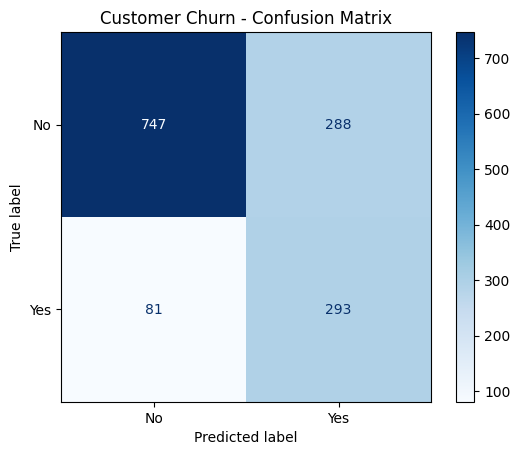

In [ ]:
# Train Final Model on Full Training Data

model.fit(X_train, y_train)

# Predict Probabilities

yes_index = list(model.classes_).index("Yes")

y_test_prob = model.predict_proba(X_test)[:, yes_index]

# Apply Selected Threshold

final_threshold = 0.50

y_test_pred = np.where(
    y_test_prob >= final_threshold,
    "Yes",
    "No"
)

# Classification Report

print("Final Classification Report:")
print(
    classification_report(
        y_test,
        y_test_pred
    )
)

# Confusion Matrix

cm = confusion_matrix(
    y_test,
    y_test_pred,
    labels=["No", "Yes"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No", "Yes"]
)

disp.plot(cmap="Blues")

plt.title("Customer Churn - Confusion Matrix")
plt.show()